#  Reducer 이해하기 - 기본 동작

**Reducer**가 지정되지 않으면, 노드의 반환값이 기존 상태를 **완전히 덮어씁니다**.

In [13]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    # 그래프 전체에서 노드들이 공유하는 state 구조
    value1: int          # 리듀서 없음 -> 새 값으로 그냥 덮어씌워짐(교체)
    value2: list[str]    # 리듀서 없음 -> 이 필드도 마찬가지로 덮어씌워짐 (누적 X)

def node_a(state: State):
    print(f"Node A 에 입력된 상태: {state}")
    # 그래프 시작 직후라 state는 invoke()에 넣은 초기값 그대로임

    # value1만 업데이트 (value2는 영향 없음)
    # -> 주석은 "value1만 바뀐다"는 의도지만, 실제로는 리듀서가 없으므로
    #    여기서 반환하는 value2도 다음 노드에 전달되는 state에 그대로 "덮어쓰기"됨
    return {"value1": 100, "value2": ["첫번째 노드"]}

def node_b(state: State):
    # 이 시점의 state는 node_a가 반환한 값으로 교체된 상태
    # (value1=100, value2=["첫번째 노드"])
    print(f"Node B 에 입력된 상태: {state}")

    # 여기서도 마찬가지로 value1, value2 둘 다 새 값으로 통째로 교체됨
    return {"value1": 200, "value2": ["두번째 노드"]}

# 그래프 구성
graph_builder = StateGraph(State)
graph_builder.add_node("node_a", node_a)  # "node_a"라는 이름으로 노드 등록
graph_builder.add_node("node_b", node_b)  # "node_b"라는 이름으로 노드 등록

graph_builder.add_edge(START, "node_a")     # 그래프 실행 시 node_a부터 시작
graph_builder.add_edge("node_a", "node_b")  # node_a 끝나면 node_b 실행
graph_builder.add_edge("node_b", END)       # node_b 끝나면 그래프 종료

graph = graph_builder.compile()  # 실행 가능한 그래프 객체로 컴파일

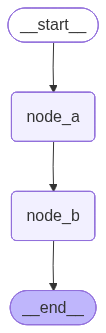

In [2]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(e)

In [3]:
initial_state = {"value1": 1, "value2": ["초기", "값"]}
result = graph.invoke(initial_state)
print("\n최종 결과:", result)

Node A 에 입력된 상태: {'value1': 1, 'value2': ['초기', '값']}
Node B 에 입력된 상태: {'value1': 100, 'value2': ['첫번째 노드']}

최종 결과: {'value1': 200, 'value2': ['두번째 노드']}


# Reducer 지정하기 - operator.add

**Reducer**를 지정하면 업데이트 방식을 제어할 수 있습니다.

# 리듀서 함수 직접 만들기

In [ ]:
def add_values(x: int, y: int) -> int:
    # 커스텀 리듀서 함수 1: 두 정수를 더해서 반환
    # x: 기존 state에 있던 값, y: 노드가 새로 반환한 값
    return x + y

def add_lists(x: list[str], y: list[str]) -> list[str]:
    # 커스텀 리듀서 함수 2: 두 리스트를 이어붙여서 반환 (x 뒤에 y를 연결)
    return x + y

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class State(TypedDict):
    # Annotated[타입, 리듀서함수] 형태로 "이 필드는 새 값이 들어올 때 이 함수로 병합하라"고 지정
    value1: Annotated[int, add_values]        # 노드가 반환한 값 = 기존값 + 새값 (누적 합산)
    value2: Annotated[list[str], add_lists]   # 노드가 반환한 값 = 기존 리스트 + 새 리스트 (누적 연결)

def node_a(state: State):
    print(f"Node A에 입력된 상태: {state}")
    # invoke()에 넣은 초기값이 그대로 들어옴

    return {"value1": 10, "value2": ["A"]}
    # 반환값이 그대로 덮어써지지 않고, add_values(기존값1, 10) / add_lists(기존["시작"], ["A"]) 로 처리됨

def node_b(state: State):
    print(f"Node B에 입력된 상태: {state}")
    # node_a 결과가 리듀서로 병합된 후의 state가 들어옴

    return {"value1": 20, "value2": ["B", "C"]}
    # 마찬가지로 add_values(이전합, 20) / add_lists(이전리스트, ["B","C"]) 로 누적 처리됨

# 그래프 구성
graph_builder = StateGraph(State)
graph_builder.add_node("node_a", node_a)
graph_builder.add_node("node_b", node_b)
graph_builder.add_edge(START, "node_a")     # 시작 -> node_a
graph_builder.add_edge("node_a", "node_b")  # node_a -> node_b
graph_builder.add_edge("node_b", END)       # node_b -> 종료
graph = graph_builder.compile()

In [6]:
initial_state = {"value1": 5, "value2": ["초기"]}
result = graph.invoke(initial_state)
print("최종 결과:", result)

Node A에 입력된 상태: {'value1': 5, 'value2': ['초기']}
Node B에 입력된 상태: {'value1': 15, 'value2': ['초기', 'A']}
최종 결과: {'value1': 35, 'value2': ['초기', 'A', 'B', 'C']}


# operator.add를 리듀서 함수로 활용하기

`operator.add`를 사용하면 기존 값에 **더하기** 연산이 적용됩니다.

### operator.add 동작 방식

| 데이터 타입 | operator.add 동작 | 예시 |
|-----------|------------------|------|
| int, float | 숫자 덧셈 | 5 + 10 = 15 |
| list | 리스트 연결 | [1, 2] + [3] = [1, 2, 3] |
| str | 문자열 연결 | "hello" + " world" |

In [ ]:
from operator import add
# operator 모듈의 add 함수: a + b를 그대로 수행하는 내장 함수
# int끼리는 덧셈, list끼리는 리스트 연결(+)이 되므로
# 앞서 직접 만든 add_values, add_lists를 대체할 수 있음 (코드 중복 줄이기)

from typing import Annotated
from typing_extensions import TypedDict

class State(TypedDict):
    value1: Annotated[int, add]        # 새 값이 들어오면 기존값 + 새값 (숫자 누적 합산)
    value2: Annotated[list[str], add]  # 새 값이 들어오면 기존리스트 + 새리스트 (리스트 누적 연결)

In [14]:
from langgraph.graph import StateGraph, START, END

def node_a(state: State):
    print(f"Node A에 입력된 상태: {state}")
    # 리듀서가 add이므로, 반환값이 기존 state에 "더해지는" 방식으로 처리됨
    return {"value1": 10, "value2": ["A"]}

def node_b(state: State):
    print(f"Node B에 입력된 상태: {state}")
    return {"value1": 20, "value2": ["B", "C"]}

# 그래프 구성
graph_builder = StateGraph(State)
graph_builder.add_node("node_a", node_a)
graph_builder.add_node("node_b", node_b)
graph_builder.add_edge(START, "node_a")     # 시작 -> node_a
graph_builder.add_edge("node_a", "node_b")  # node_a -> node_b
graph_builder.add_edge("node_b", END)       # node_b -> 종료
graph = graph_builder.compile()

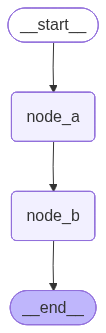

In [15]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print(e)

In [16]:
initial_state = {"value1": 5, "value2": ["초기"]}
result = graph.invoke(initial_state)
print("최종 결과:", result)

Node A에 입력된 상태: {'value1': 5, 'value2': ['초기']}
Node B에 입력된 상태: {'value1': 10, 'value2': ['A']}
최종 결과: {'value1': 20, 'value2': ['B', 'C']}


---

# 리듀서(add_messages)를 활용한 멀티턴 챗봇 예제

In [17]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI
import gradio as gr

# 1. State 정의
class State(TypedDict):
    messages: Annotated[list, add_messages]  # 새 메시지가 기존 리스트에 누적됨

# 2. LLM 준비
llm = ChatOpenAI(model="gpt-5-mini")

# 3. 노드 정의 (LLM 호출만 담당)
def chatbot_node(state: State):
    response = llm.invoke(state["messages"])  # 전달받은 전체 대화 내역으로 LLM 호출
    return {"messages": [response]}  # 새 응답만 반환 -> 리듀서가 자동 누적

# 4. 그래프 구성 (체크포인터 없음 -> 그래프 자체는 대화를 기억하지 않음)
graph_builder = StateGraph(State)
graph_builder.add_node("chatbot", chatbot_node)
graph_builder.add_edge(START, "chatbot")
graph_builder.add_edge("chatbot", END)
graph = graph_builder.compile()

# 5. Gradio 콜백 함수
def chat(user_input: str, history):
    # history: Gradio가 관리하는 이전 대화 기록 (type="messages"면 [{"role":..., "content":...}] 형태)
    # 매번 history + 새 입력을 합쳐서 messages로 통째로 넘김
    # -> 그래프 자체는 기억력이 없지만, 매번 "전체 대화"를 다시 넣어주므로 결과적으로 맥락이 유지됨
    messages = history + [{"role": "user", "content": user_input}]

    result = graph.invoke({"messages": messages})

    return result["messages"][-1].content  # 마지막 메시지(AI 응답)의 텍스트만 반환

# 6. Gradio 채팅 UI 실행
gr.ChatInterface(chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.
